# Gaussian Mixture Models & Density Estimation

**Objective:** Estimate a multimodal normal-density model for network traffic and identify low-log-density observations as anomalies.

Model complexity is selected with BIC; AIC is reported as a secondary diagnostic. The GMM itself is fit without using anomaly labels.

In [1]:

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score, precision_recall_curve

warnings.filterwarnings("ignore")


PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.anomaly_detection.metrics import evaluate_binary_predictions, select_percentile_threshold
from src.anomaly_detection.visualization import configure_plot_style, save_figure

configure_plot_style()
RANDOM_STATE = 42
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
from sklearn.mixture import GaussianMixture

DATA_PATH = PROJECT_ROOT / "data" / "Train.csv"

LABEL_CANDIDATES = ["label", "Label", "class", "Class", "attack", "Attack"]
N_COMPONENTS = range(1, 9)
COVARIANCE_TYPES = ["full", "diag"]
SAMPLE_LIMIT = 60000


In [4]:
df = pd.read_csv(DATA_PATH)

label_col = next((c for c in LABEL_CANDIDATES if c in df.columns), None)
if label_col is None:
    raise ValueError(
        "Could not identify a label column. Set label_col explicitly after inspecting df.columns."
    )

# Treat label as 0 = normal, 1 = anomaly. The mapping may need to be changed for a dataset-specific schema.
y_raw = df[label_col]
X = df.drop(columns=[label_col]).select_dtypes(include=np.number).copy()
X = X.replace([np.inf, -np.inf], np.nan).fillna(X.median(numeric_only=True))

# Common encodings: 0/1 or string labels where 'normal'/'benign' represents inliers.
if pd.api.types.is_numeric_dtype(y_raw):
    y = (y_raw.astype(float) != 0).astype(int).to_numpy()
else:
    normal_tokens = {"normal", "benign", "0", "normal traffic", "normal."}
    y = (~y_raw.astype(str).str.strip().str.lower().isin(normal_tokens)).astype(int).to_numpy()

y = np.asarray(y, dtype=int)

#  The sampling is random and reproducible.
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X), size=min(SAMPLE_LIMIT, len(X)), replace=False)
X = X.iloc[idx].reset_index(drop=True)
y = y[idx]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Numeric features: {X.shape[1]}; rows: {len(X):,}; anomaly prevalence: {y.mean():.3%}")

Numeric features: 38; rows: 25,192; anomaly prevalence: 46.614%


In [6]:
selection_rows = []
for n_components in N_COMPONENTS:
    for covariance_type in COVARIANCE_TYPES:
        gmm = GaussianMixture(
            n_components=n_components,
            covariance_type=covariance_type,
            n_init=3,
            random_state=RANDOM_STATE,
            reg_covar=1e-5,
        )
        gmm.fit(X_train_s)
        selection_rows.append({
            "n_components": n_components,
            "covariance_type": covariance_type,
            "bic": gmm.bic(X_train_s),
            "aic": gmm.aic(X_train_s),
            "lower_bound": gmm.lower_bound_,
        })

selection_df = pd.DataFrame(selection_rows).sort_values("bic")
selection_df.head(10)

,n_components,covariance_type,bic,aic,lower_bound
14,8,full,-3.957061e+06,-4.006016e+06,106.343038
10,6,full,-3.899109e+06,-3.935823e+06,104.403116
15,8,diag,-3.841544e+06,-3.846369e+06,101.820502
8,5,full,-3.762169e+06,-3.792762e+06,100.575860
13,7,diag,-3.656600e+06,-3.660821e+06,96.906287
12,7,full,-3.592761e+06,-3.635595e+06,96.497093
11,6,diag,-3.558066e+06,-3.561683e+06,94.278738
9,5,diag,-3.429861e+06,-3.432874e+06,90.865856
7,4,diag,-3.422305e+06,-3.424714e+06,90.645878
6,4,full,-3.272051e+06,-3.296525e+06,87.401759


In [8]:
best = selection_df.iloc[0]
gmm = GaussianMixture(
    n_components=int(best["n_components"]),
    covariance_type=best["covariance_type"],
    n_init=5,
    random_state=RANDOM_STATE,
    reg_covar=1e-5,
)
start = time.perf_counter()
gmm.fit(X_train_s)
fit_seconds = time.perf_counter() - start

# score_samples returns log-density. Lower density is more anomalous.
train_log_density = gmm.score_samples(X_train_s)
test_log_density = gmm.score_samples(X_test_s)
# The threshold is learned from the normal subset of training data only.
normal_train_density = train_log_density[y_train]
threshold = np.percentile(normal_train_density, 1.0)
test_anomaly_score = -test_log_density
test_pred = (test_log_density < threshold).astype(int)
metrics = evaluate_binary_predictions(y_test, test_pred, test_anomaly_score)

print(f"Selected n_components={int(best['n_components'])}, covariance={best['covariance_type']}")
print(f"BIC={best['bic']:.2f}, AIC={best['aic']:.2f}, fit={fit_seconds:.3f}s")
print(f"1st-percentile normal log-density threshold={threshold:.4f}")
print(metrics)

Selected n_components=8, covariance=full
BIC=-3957060.62, AIC=-4006015.56, fit=18.043s
1st-percentile normal log-density threshold=153.9949
EvaluationResult(precision=0.33779791215284616, recall=0.5841280653950953, f1=0.42805441158118057, pr_auc=0.3964531835039802, roc_auc=0.332615832181117)


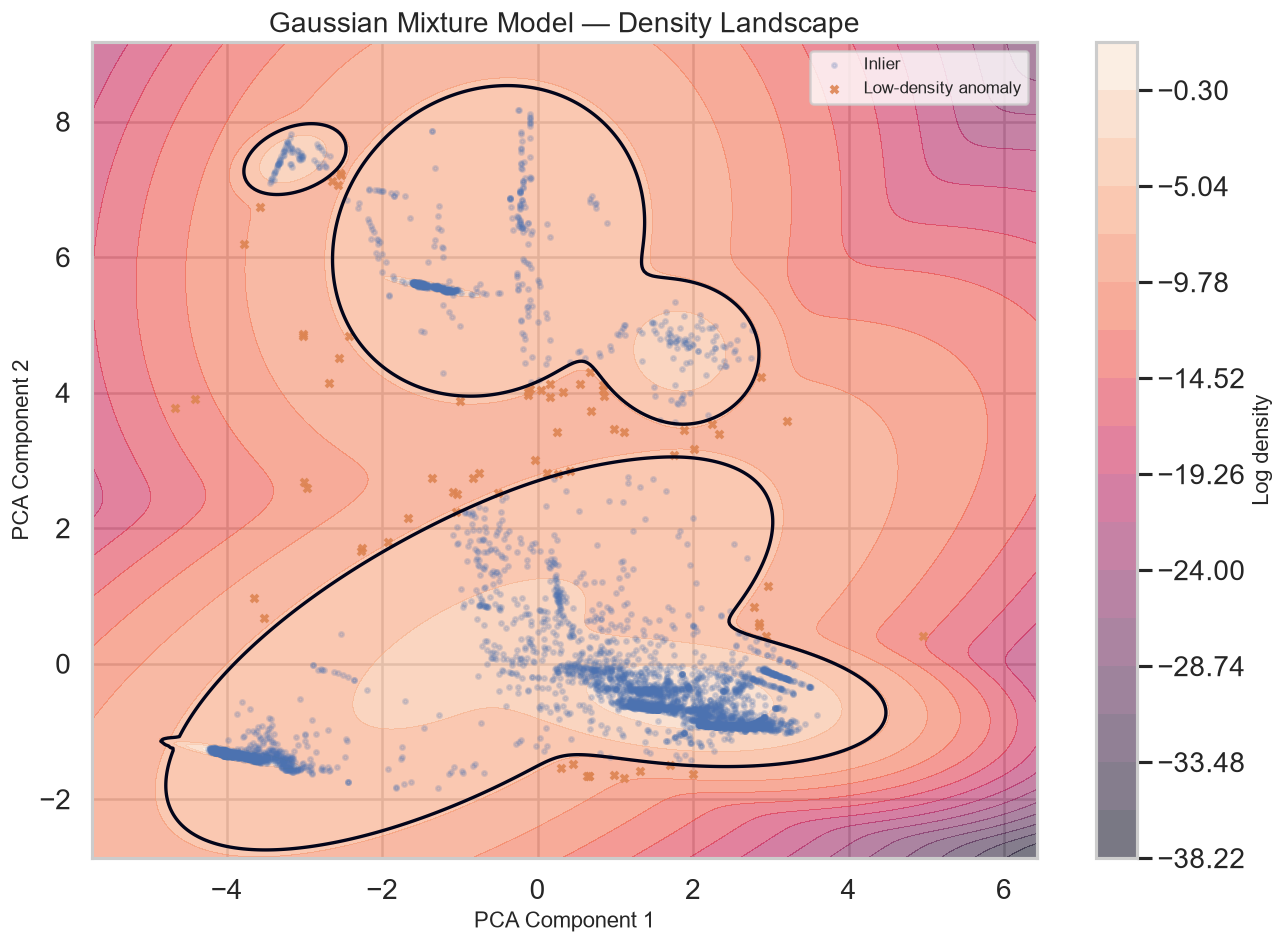

In [9]:
# Density contour visualization in a 2D PCA projection.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

viz_gmm = GaussianMixture(
    n_components=int(best["n_components"]),
    covariance_type=best["covariance_type"],
    n_init=5,
    random_state=RANDOM_STATE,
    reg_covar=1e-5,
).fit(X_train_2d)

x_min, x_max = X_train_2d[:,0].min()-1, X_train_2d[:,0].max()+1
y_min, y_max = X_train_2d[:,1].min()-1, X_train_2d[:,1].max()+1
xx, yy = np.meshgrid(np.linspace(x_min,x_max,350), np.linspace(y_min,y_max,350))
grid_log_density = viz_gmm.score_samples(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# Use the 1st percentile of the training visualization density as the contour cutoff.
viz_threshold = np.percentile(viz_gmm.score_samples(X_train_2d), 1)
flagged = viz_gmm.score_samples(X_test_2d) < viz_threshold

fig, ax = plt.subplots(figsize=(11, 8))
levels = np.linspace(np.nanmin(grid_log_density), np.nanmax(grid_log_density), 18)
contours = ax.contourf(xx, yy, grid_log_density, levels=levels, alpha=0.55)
fig.colorbar(contours, ax=ax, label="Log density")
ax.scatter(X_test_2d[~flagged,0], X_test_2d[~flagged,1], s=7, alpha=0.20, label="Inlier")
ax.scatter(X_test_2d[flagged,0], X_test_2d[flagged,1], s=18, marker="x", alpha=0.9, label="Low-density anomaly")
ax.contour(xx, yy, grid_log_density, levels=[viz_threshold], linewidths=2.0)
ax.set_title("Gaussian Mixture Model — Density Landscape")
ax.set_xlabel("PCA Component 1")
ax.set_ylabel("PCA Component 2")
ax.legend()
fig.tight_layout()
save_figure(fig, FIG_DIR / "gmm_density_contours")
plt.show()

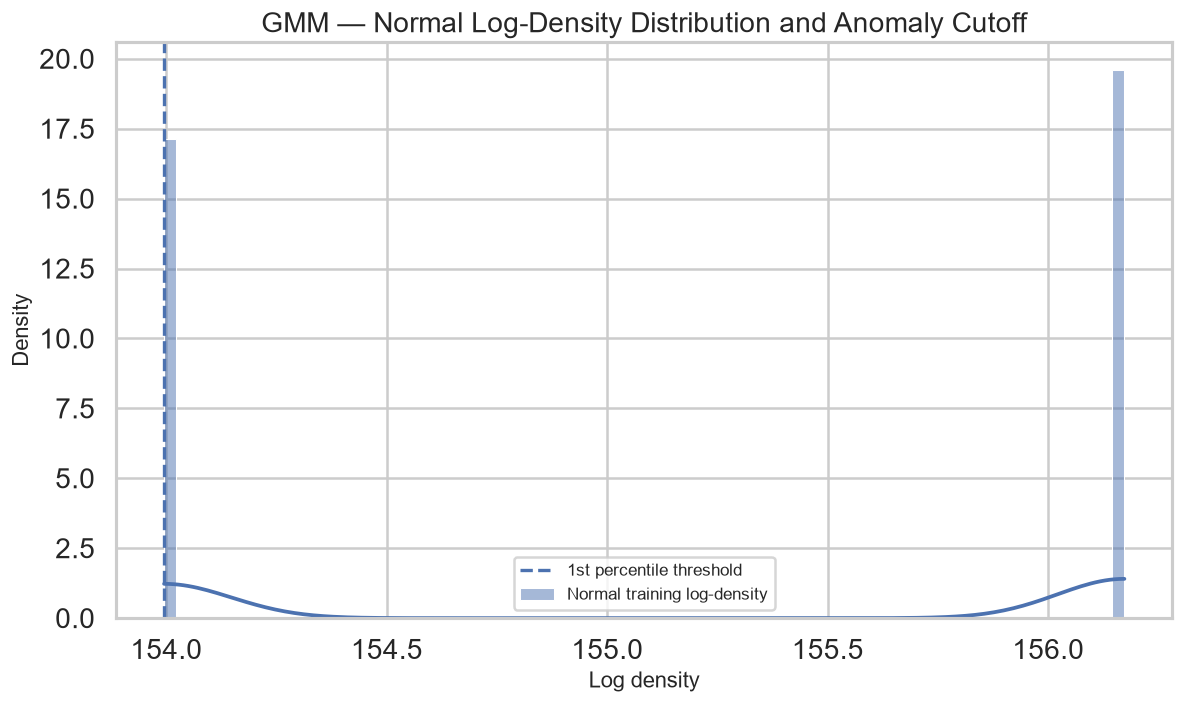

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.histplot(train_log_density[y_train], bins=80, stat="density", kde=True, ax=ax, label="Normal training log-density")
ax.axvline(threshold, linestyle="--", linewidth=2, label="1st percentile threshold")
ax.set_title("GMM — Normal Log-Density Distribution and Anomaly Cutoff")
ax.set_xlabel("Log density")
ax.legend()
fig.tight_layout()
save_figure(fig, FIG_DIR / "gmm_log_density_threshold")
plt.show()